# 05 · Real match — UD Mansores vs Canedo FC (CFC TV stream)

First real recording in the target format: **one panning/zooming camera, 640 × 360, no score bug, no audio**
(full profile in `docs/RECORDING_PROFILE.md`). This notebook checks, on a processed segment:

1. the **PTZ camera tracker** (is the pitch template on the painted lines? how often? does it drift?),
2. **detection + team assignment** at this resolution,
3. **positions on the pitch** (are players inside the measured pitch?),
4. the **ball** (motion-compensated candidates) and what the analytics can say from this segment.

Inputs are produced by `run_analysis.py --video ... --config configs/canedo_segment.yaml --out outputs/canedo_segment`.

In [1]:
import sys, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
from football_eval.config import load_config, resolve_path
from football_eval.perception import load_perception
from football_eval.ptz import load_ptz, draw_template
from football_eval.pitch import Pitch, draw_pitch
from football_eval.video import read_frame
VIDEO = ROOT / "data/videos/2026-10-18_UD_Mansores_vs_Canedo_FC_J2.mp4"
OUT = ROOT / "outputs/canedo_segment"
cfg = load_config(ROOT / "configs/canedo_segment.yaml")
cam, anchors = load_ptz(resolve_path(cfg.pitch.calibration_file))
pitch = cam.pitch
p = load_perception(str(OUT))
tr, ball, frames = p["tracks"], p["ball"], p["frames"]
camlog = pd.read_csv(OUT / "camera_log.csv")
camlog["t"] = frames.set_index("frame").t.reindex(camlog.frame).to_numpy()
print(f"camera: C = {np.round(cam.C, 2)} m, roll = {np.degrees(cam.roll):.2f} deg, pitch {pitch.length:.1f} x {pitch.width:.1f} m")
print(f"segment {frames.t.min()/60:.1f}-{frames.t.max()/60:.1f} min of the video, {len(frames)} analysed frames, {len(tr):,} person detections")

camera: C = [51.75 -2.56  3.95] m, roll = -0.89 deg, pitch 105.4 x 61.6 m
segment 15.0-25.0 min of the video, 3000 analysed frames, 44,665 person detections


## 1 · Camera tracking — template overlay on sampled frames

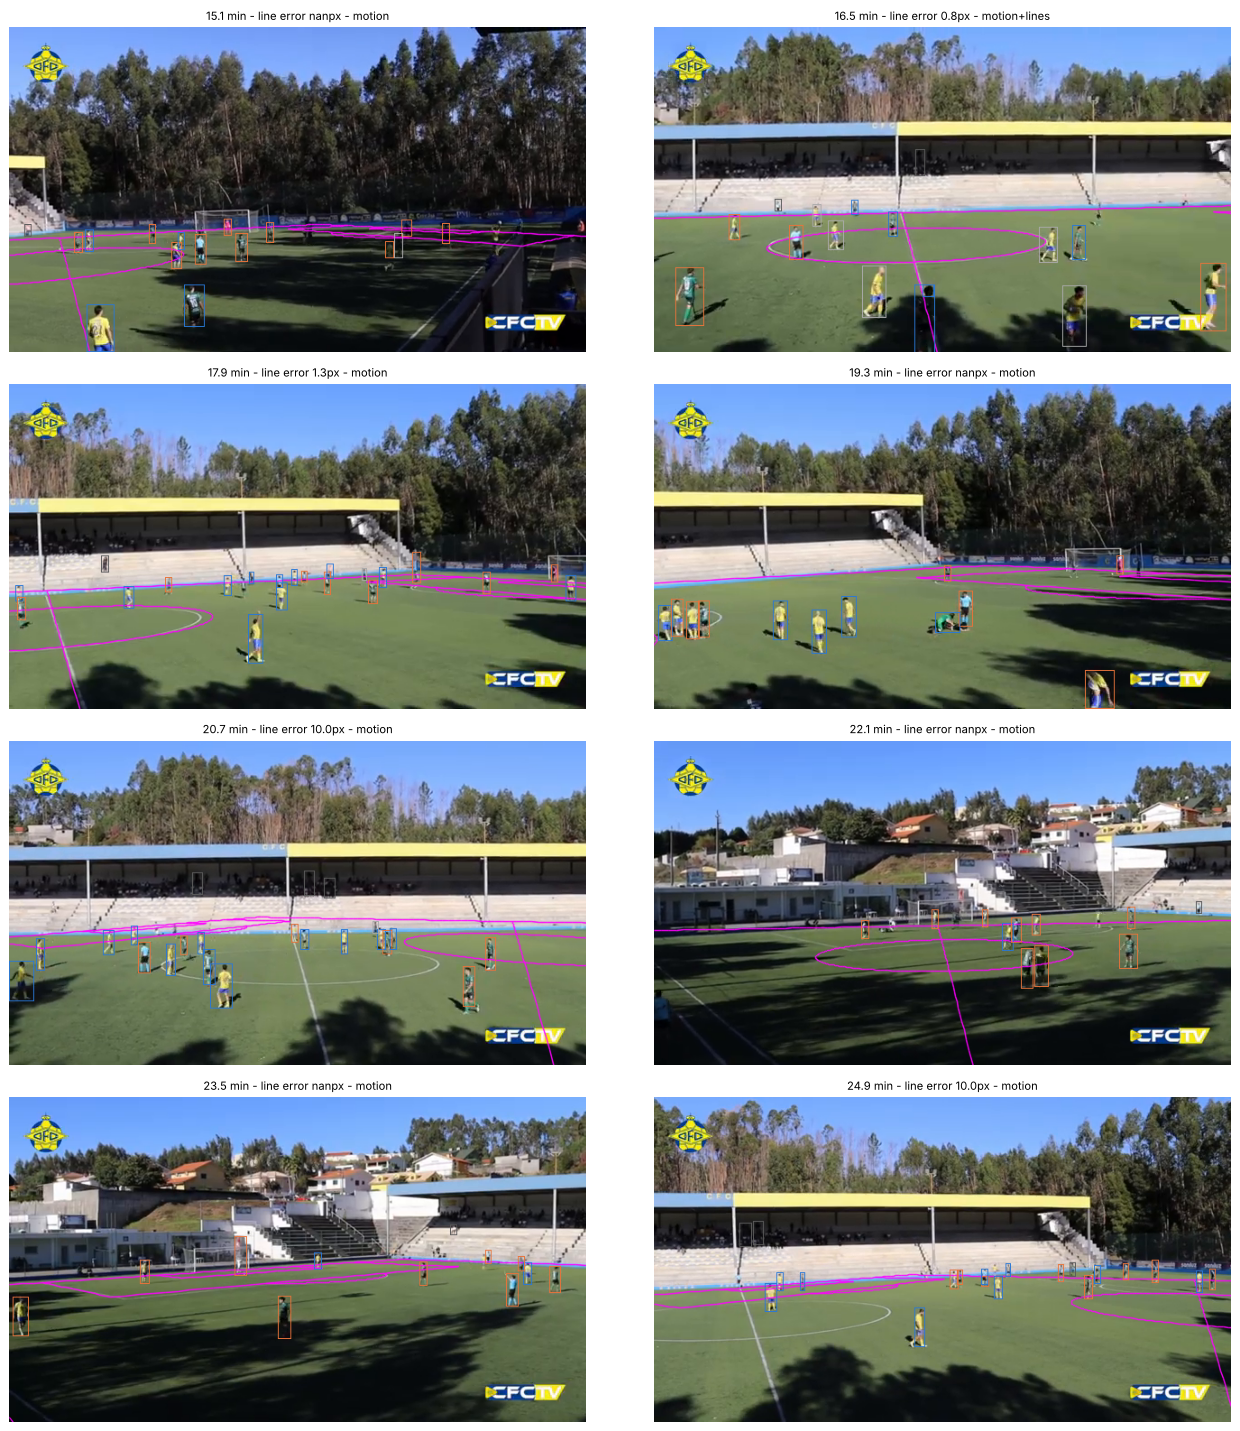

In [2]:
COL = {0: (214, 120, 42), 1: (59, 116, 232), -1: (170, 170, 170)}
ts = np.linspace(frames.t.min() + 5, frames.t.max() - 5, 8)
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
for ax, t in zip(axes.ravel(), ts):
    k = int(np.argmin(np.abs(camlog.t - t)))
    r = camlog.iloc[k]; f = int(r.frame); tt = float(r.t)
    img = read_frame(str(VIDEO), tt)
    v = draw_template(img, cam, (r.pan, r.tilt, r.f)) if np.isfinite(r.pan) else img
    for _, q in tr[tr.frame == f].iterrows():
        c = (90, 90, 90) if q.cls == "outside" else COL.get(int(q.team), COL[-1])
        cv2.rectangle(v, (int(q.x0), int(q.y0)), (int(q.x1), int(q.y1)), c, 1)
    ax.imshow(v[..., ::-1]); ax.axis("off")
    ax.set_title(f"{tt/60:.1f} min - line error {r.line_err:.1f}px - {r.src}", fontsize=9)
plt.tight_layout()

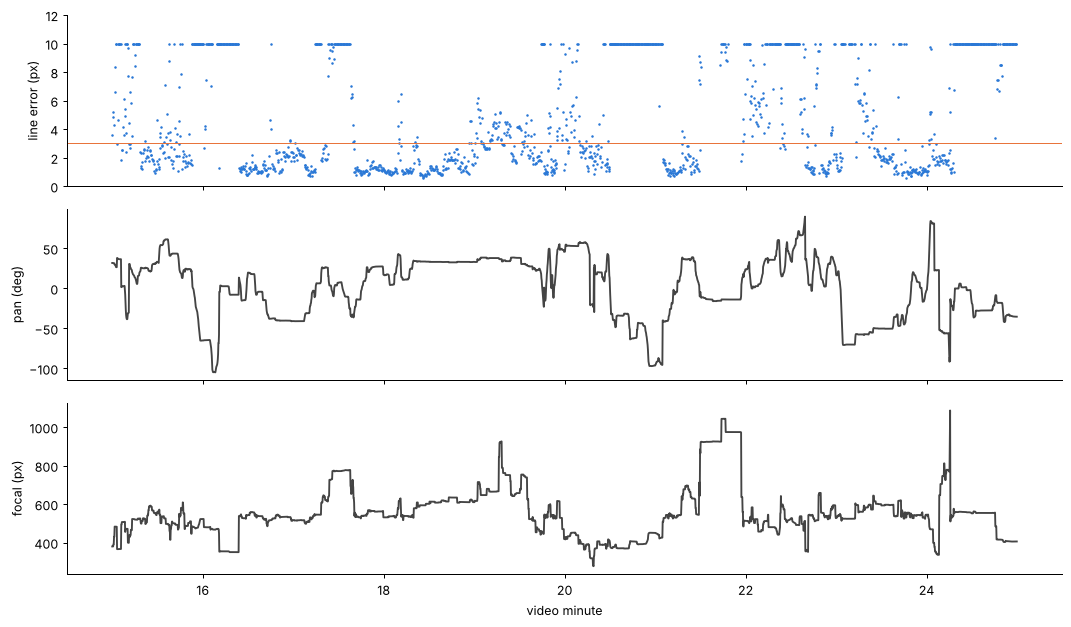

,frames,with line check,median error px,checked frames < 3 px,checked frames < 5 px,relocalisations,global recoveries
camera tracker,3000.0,1603.0,2.952,0.506,0.611,14.0,17.0


In [3]:
e = camlog.line_err
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
x = camlog.t / 60
ax[0].plot(x, e, ".", ms=2, color="#2a78d6"); ax[0].axhline(3, color="#e8743b", lw=0.8); ax[0].set_ylabel("line error (px)")
ax[0].set_ylim(0, 12)
ax[1].plot(x, np.degrees(camlog.pan), color="#444"); ax[1].set_ylabel("pan (deg)")
ax[2].plot(x, camlog.f, color="#444"); ax[2].set_ylabel("focal (px)"); ax[2].set_xlabel("video minute")
plt.tight_layout()
ec = e.dropna()
summary = pd.Series({"frames": len(camlog), "with line check": len(ec),
                     "median error px": float(ec.median()), "checked frames < 3 px": float((ec < 3).mean()),
                     "checked frames < 5 px": float((ec < 5).mean()),
                     "relocalisations": int((camlog.src == "relocalized").sum()),
                     "global recoveries": int((camlog.src == "global").sum())})
summary.to_frame("camera tracker").T

## 2 · Detection and teams

people per frame (median) by team label: {-1: 1.0, 0: 5.0, 1: 7.0}
share of detections outside the pitch (bench, crowd, staff): 0.109
tracks with a team label: 1649 of 2103


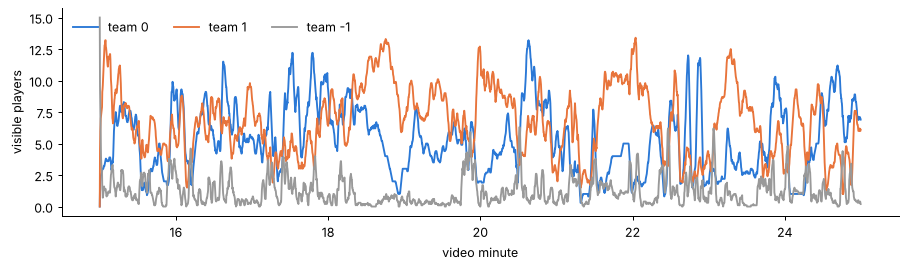

In [4]:
inside = tr[tr.cls != "outside"]
per_frame = inside.groupby(["frame", "team"]).size().unstack(fill_value=0)
print("people per frame (median) by team label:", per_frame.median().to_dict())
print("share of detections outside the pitch (bench, crowd, staff):", round(float((tr.cls == "outside").mean()), 3))
print(f"tracks with a team label: {inside[inside.team >= 0].track_id.nunique()} of {inside.track_id.nunique()}")
fig, ax = plt.subplots(figsize=(12, 3))
tt = frames.set_index("frame").t.reindex(per_frame.index) / 60
for tm, c in ((0, "#2a78d6"), (1, "#e8743b"), (-1, "#999999")):
    if tm in per_frame:
        ax.plot(tt, per_frame[tm].rolling(10, min_periods=1).mean(), color=c, label=f"team {tm}")
ax.set_ylabel("visible players"); ax.set_xlabel("video minute"); ax.legend(frameon=False, ncol=3);

## 3 · Positions on the measured pitch

frames with a usable camera pose: 63%
99.1% of the player positions kept fall inside the pitch (+1 m)


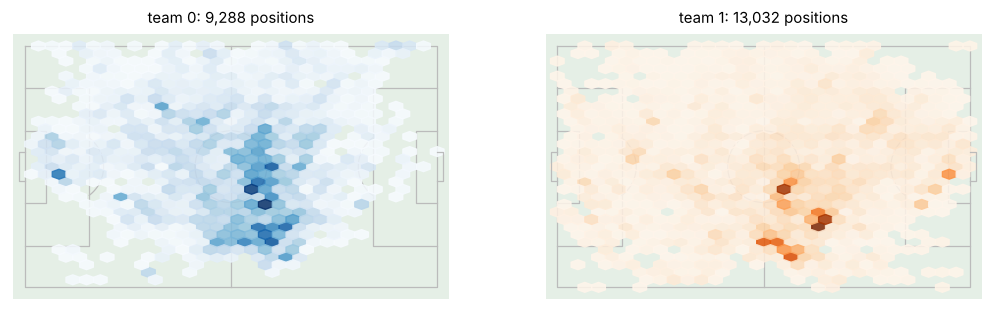

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for tm, ax in zip((0, 1), axes):
    q = inside[(inside.team == tm) & inside.x.notna()]
    draw_pitch(ax, pitch)
    ax.hexbin(q.x, q.y, gridsize=(30, 16), extent=(0, pitch.length, 0, pitch.width),
              cmap="Blues" if tm == 0 else "Oranges", mincnt=1, alpha=0.85)
    ax.set_ylim(pitch.width + 4, -4); ax.set_title(f"team {tm}: {len(q):,} positions")
pos = inside[inside.x.notna()]
ok = pitch.in_pitch(pos.x, pos.y, 1.0).mean()
print(f"frames with a usable camera pose: {frames.cam_ok.mean():.0%}" if "cam_ok" in frames else "")
print(f"{ok:.1%} of the player positions kept fall inside the pitch (+1 m)")

## 4 · Ball

a ball candidate was kept in 37% of frames (gap-filled: 63%) - candidates are noisy at 640x360, so the track below is indicative


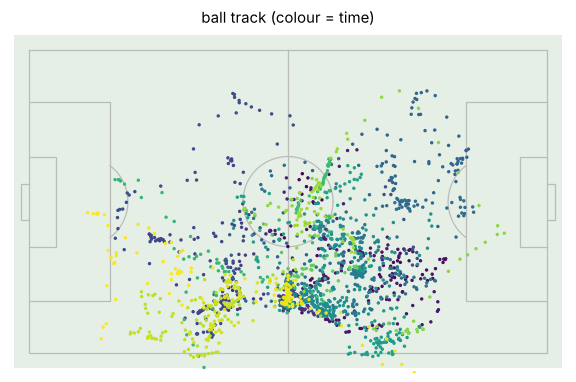

In [6]:
print(f"a ball candidate was kept in {ball.visible.mean():.0%} of frames (gap-filled: {ball.valid.mean():.0%}) - "
      "candidates are noisy at 640x360, so the track below is indicative")
fig, ax = plt.subplots(figsize=(8, 5)); draw_pitch(ax, pitch)
b = ball[ball.valid]
ax.scatter(b.x, b.y, s=3, c=b.t, cmap="viridis"); ax.set_title("ball track (colour = time)");

## 5 · Analytics on the segment (indicative)

In [7]:
from football_eval.analytics import run_analytics
r = run_analytics(tr, ball, cfg, root=str(ROOT))
r["team_stats"].loc[["possession_%", "passes", "pass_accuracy_%", "shots", "xG", "throw_ins",
                     "distance_covered_km(tracked)", "block_depth_m", "block_width_m", "team_centroid_x_m"]].round(2)

,Canedo FC,UD Mansores
possession_%,28.80,71.20
passes,33.00,69.00
pass_accuracy_%,33.33,62.32
shots,1.00,0.00
xG,0.02,0.00
throw_ins,0.00,0.00
distance_covered_km(tracked),4.72,6.29
block_depth_m,21.42,26.61
block_width_m,26.09,25.29
team_centroid_x_m,54.09,47.96


## Reading the results
* **Camera tracking** is the foundation: when the template sits on the lines (error below ~3 px), positions are good
  to about 1 m in the near half and a few metres near the far touchline (low camera, 640 x 360). Fast pans and long
  spells without visible markings are where drift starts; relocalisation recovers most of it.
* **Teams**: yellow vs green-black separate well in sunlight; shade and the 2nd half (sunset) are the hard part.
* **Ball**: the main limitation at 640 x 360 - candidates are noisy, so possession, passes and shots from this
  recording are *indicative only*. A 720p/1080p download of the same stream would change this the most.
* Position-based statistics (team shape, territory, distance covered while in view) are already usable.